# Speech Emotion Recognition Model Training

## Overview

In this project, we aim to classify emotions from audio data using machine learning models. The RAVDESS dataset serves as the foundation, with extracted audio features (e.g., MFCCs) used to train and evaluate three distinct deep learning architectures. Each architecture will be associated with one team member, highlighting its unique strengths and limitations:

---

## Models and Responsibilities

1. **CNN (Sydney)**:
   - **Purpose**: Convolutional Neural Networks are used to capture spatial patterns in the extracted audio features.
   - **Strengths**: Effective for static feature representation (e.g., MFCCs or spectrograms).
   - **Limitation**: CNNs struggle to capture temporal dependencies in sequential data.

2. **RNN (Ryan)**:
   - **Purpose**: Recurrent Neural Networks are designed to model temporal dependencies and sequential data, making them a natural choice for audio analysis.
   - **Strengths**: Effective for capturing patterns over time (e.g., pitch or tone variations).
   - **Limitation**: Can suffer from vanishing gradients in long sequences.

3. **Transformer (Edgar)**:
   - **Purpose**: Transformers leverage attention mechanisms to process audio sequences more effectively than traditional RNNs.
   - **Strengths**: High performance on sequential data with parallelized computations.
   - **Limitation**: Computationally intensive and requires larger datasets for training.

---

## Objective

We aim to evaluate the performance of these models on Speech Emotion Recognition and determine which architecture is best suited for this task. Each team member will focus on the following:

- **Sydney**: Optimize and evaluate the CNN model.
- **Ryan**: Implement and train the RNN model.
- **Edgar**: Explore the capabilities of the Transformer model.

---

## Dataset

- **RAVDESS**: A dataset of emotional speech audio files, each labeled with one of eight emotions (e.g., happy, sad, angry).

---

## Evaluation Metrics

The models will be evaluated using:
- **Accuracy**: Percentage of correctly classified samples.
- **Confidence Scores**: Model certainty in predictions.
- **Qualitative Analysis**: Playback of predicted samples for subjective evaluation.

---

## Conclusion

By comparing these architectures, we aim to gain insights into their strengths and limitations for Speech Emotion Recognition, ultimately guiding future work in audio-based emotion analysis.

---


In [1]:
#pip install librosa matplotlib scikit-learn torch torchaudio tensorflow kagglehub


# Import libraries
import os
import librosa
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import torch
import torch.nn as nn
import torch.optim as optim


# Data Preparation for Speech Emotion Recognition

## Overview

This script prepares the RAVDESS dataset for training and evaluating a Speech Emotion Recognition (SER) model. It loads audio data, extracts features (MFCCs), and splits the data into training and testing sets for further use in a machine learning pipeline.

---

## Key Steps

1. **Dataset Download**:
   - The RAVDESS dataset is downloaded using `kagglehub`.

2. **Emotion Mapping**:
   - Each audio file is labeled with one of the following emotions:
     - Neutral, Calm, Happy, Sad, Angry, Fearful, Disgust, Surprised.

3. **Feature Extraction**:
   - **MFCCs (Mel-Frequency Cepstral Coefficients)** are extracted from each audio file using `librosa`.
   - The mean of the MFCC coefficients across frames is used as the feature representation.

4. **Data Loading**:
   - Audio files are processed, and their corresponding MFCC features and labels are stored in arrays.

5. **Label Encoding**:
   - Emotion labels are encoded into numerical values using `LabelEncoder`.

6. **Train/Test Split**:
   - The data is split into 80% training and 20% testing using `train_test_split`.

7. **Tensor Conversion**:
   - The features (`X`) and labels (`y`) are converted into PyTorch tensors for use in deep learning models.

---

## Example Output

After running the script, you will see:
- The number of training and testing samples:


In [2]:
import os
import librosa
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import torch

# Download the RAVDESS dataset using kagglehub
import kagglehub

# Download latest version
dataset_path = kagglehub.dataset_download("uwrfkaggler/ravdess-emotional-speech-audio")

# Check the path to the dataset files
print("Path to dataset files:", dataset_path)

# Emotion mapping
emotions = {
    '01': 'neutral', '02': 'calm', '03': 'happy', '04': 'sad',
    '05': 'angry', '06': 'fearful', '07': 'disgust', '08': 'surprised'
}

# Function to load audio data and extract MFCCs
def load_data(dataset_path):
    data = []
    labels = []
    for root, _, files in os.walk(dataset_path):
        for file in files:
            if file.endswith('.wav'):
                file_path = os.path.join(root, file)
                # Extract emotion from the filename
                emotion = emotions.get(file.split("-")[2])
                if emotion:  # Only process files with valid emotion codes
                    audio, sr = librosa.load(file_path, sr=22050)
                    mfccs = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=13).mean(axis=1)
                    data.append(mfccs)
                    labels.append(emotion)
    return np.array(data), np.array(labels)

# Load and preprocess dataset
X, y = load_data(dataset_path)

# Encode labels
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

# Split into train/test sets
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, random_state=42)

# Convert to PyTorch tensors
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

print(f"Data loaded successfully! Training samples: {len(X_train)}, Test samples: {len(X_test)}")


Path to dataset files: C:\Users\ruiz\.cache\kagglehub\datasets\uwrfkaggler\ravdess-emotional-speech-audio\versions\1
Data loaded successfully! Training samples: 2304, Test samples: 576


# ImprovedCNNModel for Speech Emotion Recognition

## Overview

This is a Convolutional Neural Network (CNN) designed for classifying emotions in speech data. The model takes input features (e.g., MFCCs or spectrograms) and predicts the emotion class.

---

## Architecture

1. **Convolutional Layers**:
   - Three convolutional layers with increasing filters (32, 64, 128) extract spatial features from the input.
   - Each layer uses:
     - **Kernel Size**: 3
     - **Stride**: 1
     - **Padding**: 1
   - **ReLU Activation** is applied after each convolution.

2. **Pooling Layers**:
   - Max pooling layers reduce the spatial dimensions after each convolutional layer.

3. **Dropout Layer**:
   - A dropout rate of 0.5 prevents overfitting by randomly dropping units during training.

4. **Fully Connected Layers**:
   - First layer: Reduces feature dimensions to 256 units.
   - Second layer: Outputs predictions for the number of emotion classes.

---

## Key Features

- **Input Flexibility**: Processes audio features with one input channel (e.g., MFCCs or spectrograms).
- **Regularization**: Includes dropout to improve generalization.
- **Classification**: Outputs a probability distribution over emotion classes using the final fully connected layer.

---

## Example Usage

```python
# Instantiate the model
improved_cnn_model = ImprovedCNNModel(input_size=X_train.shape[1], num_classes=len(emotions))


In [3]:
class ImprovedCNNModel(nn.Module):
    def __init__(self, input_size, num_classes):
        super(ImprovedCNNModel, self).__init__()
        self.conv1 = nn.Conv1d(in_channels=1, out_channels=32, kernel_size=3, stride=1, padding=1)
        self.conv2 = nn.Conv1d(in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=1)
        self.conv3 = nn.Conv1d(in_channels=64, out_channels=128, kernel_size=3, stride=1, padding=1)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool1d(kernel_size=2)
        self.dropout = nn.Dropout(0.5)
        self.fc1 = nn.Linear((input_size // 8) * 128, 256)  # Adjust size based on pooling
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = x.unsqueeze(1)  # Add channel dimension
        x = self.conv1(x)
        x = self.relu(x)
        x = self.pool(x)
        x = self.conv2(x)
        x = self.relu(x)
        x = self.pool(x)
        x = self.conv3(x)
        x = self.relu(x)
        x = self.pool(x)
        x = x.view(x.size(0), -1)  # Flatten
        x = self.dropout(x)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        return x

# Instantiate the model
improved_cnn_model = ImprovedCNNModel(input_size=X_train.shape[1], num_classes=len(emotions))



# Evaluation Function for Speech Emotion Recognition

## Overview

This function evaluates the performance of a trained CNN model on Speech Emotion Recognition (SER) by:

1. Predicting the emotions for a specified number of test samples (`runs`).
2. Displaying the **true emotion**, **predicted emotion**, and the **confidence level** of each prediction.
3. Playing the corresponding audio sample for qualitative analysis.

---

## Key Features

1. **Batch Processing**:
   - Processes `runs` samples in a single forward pass through the model for efficiency.

2. **Prediction Confidence**:
   - Calculates the confidence level as the maximum probability for each predicted class.

3. **Audio Playback**:
   - Locates and plays the audio file for each test sample, enabling qualitative assessment of predictions.

---

## Example Usage

```python
# Evaluate the first 10 samples
evaluate_audio_sample(improved_cnn_model, X_test, y_test, encoder, dataset_path, runs=10)


In [4]:
from IPython.display import Audio, display
import torch.nn.functional as F
import numpy as np
import os

# Updated evaluation function
def evaluate_audio_sample(model, X_test, y_test, encoder, dataset_path, runs=10):
    """
    Evaluate the model on the first `runs` samples from the test set.
    Display true emotion, predicted emotion, confidence level, and play audio.
    """
    model.eval()  # Set the model to evaluation mode

    # Run the model on the first `runs` test samples
    with torch.no_grad():
        output = model(X_test[:runs])  # Forward pass for `runs` samples
        probabilities = F.softmax(output, dim=1).cpu().numpy()  # Convert logits to probabilities
        predicted_labels = np.argmax(probabilities, axis=1)  # Get predicted class indices
        confidences = np.max(probabilities, axis=1)  # Confidence is the max probability for each prediction

    # Decode true and predicted labels for `runs` samples
    true_emotions = encoder.inverse_transform(y_test[:runs].numpy())
    predicted_emotions = encoder.inverse_transform(predicted_labels)

    for i in range(runs):
        # Print the evaluation results
        print(f"\nSample {i + 1}:")
        print(f"  True Emotion: {true_emotions[i]}")
        print(f"  Predicted Emotion: {predicted_emotions[i]} (Confidence: {confidences[i]:.2f})")

        # Locate the corresponding audio file for playback
        file_name = None
        for root, _, files in os.walk(dataset_path):
            for file in files:
                # Match audio file to the true emotion
                if file.endswith('.wav') and emotions.get(file.split("-")[2]) == true_emotions[i]:
                    file_name = os.path.join(root, file)
                    break
            if file_name:
                break

        # Play the audio sample if file is found
        if file_name:
            print("Playing the audio sample...")
            display(Audio(file_name, autoplay=True))
        else:
            print("Error: Corresponding audio file not found.")

# Example usage: Evaluate the first 10 samples
evaluate_audio_sample(improved_cnn_model, X_test, y_test, encoder, dataset_path, runs=10)



Sample 1:
  True Emotion: disgust
  Predicted Emotion: angry (Confidence: 0.58)
Playing the audio sample...


<IPython.lib.display.Audio object>


Sample 2:
  True Emotion: happy
  Predicted Emotion: angry (Confidence: 0.52)
Playing the audio sample...


<IPython.lib.display.Audio object>


Sample 3:
  True Emotion: fearful
  Predicted Emotion: angry (Confidence: 0.57)
Playing the audio sample...


<IPython.lib.display.Audio object>

... (10 outputs left out)


Sample 9:
  True Emotion: disgust
  Predicted Emotion: angry (Confidence: 0.54)
Playing the audio sample...


<IPython.lib.display.Audio object>


Sample 10:
  True Emotion: neutral
  Predicted Emotion: angry (Confidence: 0.53)
Playing the audio sample...


<IPython.lib.display.Audio object>

# Evaluation of CNN Model for Speech Emotion Recognition

## Overview

This evaluation assesses a Convolutional Neural Network (CNN) for Speech Emotion Recognition (SER). The dataset contains audio samples labeled with emotions like **happy**, **angry**, and **sad**, with features extracted as MFCCs or spectrograms.

---

## Key Findings

1. **Model Behavior**:
   - The CNN correctly predicted the emotion for **1 out of 10 samples**, achieving a 10% accuracy in this evaluation.
   - The true emotions were correctly retrieved from labels, but the predicted emotions frequently lacked variation.
   - The confidence levels for incorrect predictions were often higher than 30%, suggesting the model is overconfident in its biased outputs.

2. **Limitations of CNN**:
   - CNNs excel at processing spatial features but struggle with sequential dependencies in audio.
   - Speech emotion recognition relies heavily on temporal context, better captured by sequential models like RNNs, LSTMs, or Transformers.

3. **Dataset Issues**:
   - The dataset may be imbalanced, leading the model to favor specific dominant classes.
   - Audio complexity (e.g., overlapping pitch and tone variations) requires richer feature representations beyond MFCCs or spectrograms.

---

## Conclusion

The CNN model demonstrated significant limitations for SER, capturing spatial but not temporal features of the audio data. Despite correctly classifying 2 samples, its overall performance was poor, with overfitting and bias evident in the predictions. Future models should incorporate sequential learning and advanced feature extraction to better handle speech data.

---

## Next Steps

1. **Implement Sequential Models**: Explore RNNs and Transformers for better temporal modeling.
2. **Enhance Feature Representation**: Experiment with log-mel spectrograms or pretrained embeddings like Wav2Vec.
3. **Address Class Imbalance**: Apply data augmentation or weighted loss functions to mitigate bias.

---


#ImprovedRNNModel for Speech Emotion Recognition
## Overview

This is a Recurrent Neural Network (RNN) designed for classifying emotions in speech data. The model takes input features (e.g., MFCCs) and predicts the emotion class based on sequential dependencies in the data.

---

## Architecture
1. **Recurrent Layers:**
  - A Long Short-Term Memory (LSTM) layer processes sequential information from the input features. The LSTM helps the model retain important patterns over time.
  - Hidden Size: 256 units in the hidden state.
  - Number of Layers: 2 layers for capturing complex temporal relationships.
  - Dropout: A dropout rate of 0.5 is applied between LSTM layers to prevent overfitting.

2. **Fully Connected Layers:**
      The output from the LSTM layers is passed through a fully connected layer to reduce the feature dimensions.
      The second fully connected layer outputs predictions for the number of emotion classes.

3. **Activation Functions:**
      ReLU Activation is used in the fully connected layers to introduce non-linearity and help the model learn complex relationships.

---

## Key Features

-**Sequential Processing**: The LSTM layers capture temporal dependencies in the speech data, which is crucial for understanding emotion.

-**Regularization**: Dropout is applied to prevent overfitting during training.

-**Classification**: The output layer provides a probability distribution over the possible emotion classes using the final fully connected layer.

-**Class Imbalance Handling**: The loss function includes class weights to account for potential imbalances in the dataset.

---

# Import Necissary Libraries for RNN

In [5]:
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.utils.class_weight import compute_class_weight
import torch.nn.functional as F

# Prepare the RNN input (reshape MFCC features to match [batch, seq_length, feature_dim])
seq_length = 13
feature_dim = X_train.shape[1] // seq_length  # Derived feature dimension

# Reshape the data for RNN
X_train_rnn = X_train.view(-1, seq_length, feature_dim)
X_test_rnn = X_test.view(-1, seq_length, feature_dim)

# Compute class weights for imbalanced datasets
class_weights = compute_class_weight('balanced', classes=np.unique(y_train.numpy()), y=y_train.numpy())
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to('cuda' if torch.cuda.is_available() else 'cpu')

# RNN training parameters
hidden_size = 256
num_layers = 2
learning_rate = 0.001
batch_size = 32
num_epochs = 50

# Data loaders for training and testing
train_dataset = TensorDataset(X_train_rnn, y_train)
test_dataset = TensorDataset(X_test_rnn, y_test)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)




---

## Example Usage

```python
# Instantiate the model
rnn_model = RNNModel(input_size=feature_dim, hidden_size=hidden_size, num_layers=num_layers, num_classes=len(emotions))


In [6]:
class RNNModel(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, num_classes, dropout=0.5):
        """
        RNN model with LSTM layers and a fully connected layer for classification.
        """
        super(RNNModel, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True, dropout=dropout)
        self.fc = nn.Linear(hidden_size, num_classes)
        self.dropout = nn.Dropout(dropout)  # Dropout for regularization
        self.softmax = nn.LogSoftmax(dim=1)

    def forward(self, x):
        """
        Forward pass of the RNN.
        - x: Input tensor with shape [batch_size, seq_length, feature_dim]
        """
        # Initialize hidden and cell states
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)

        # Pass through LSTM layers
        out, _ = self.lstm(x, (h0, c0))

        # Apply dropout and fully connected layer on the last time step's output
        out = self.dropout(out[:, -1, :])  # Select the last time step's output
        out = self.fc(out)
        out = self.softmax(out)
        return out

# Instantiate the model
rnn_model = RNNModel(input_size=feature_dim, hidden_size=hidden_size, num_layers=num_layers, num_classes=len(emotions))

# Define the criterion with class weights and optimizer with weight decay
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)  # Weighted loss function
optimizer = optim.Adam(rnn_model.parameters(), lr=learning_rate, weight_decay=1e-5)  # Weight decay for regularization
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.7)  # Learning rate scheduler


## Train the Model

In [7]:
def train_rnn_model(model, train_loader, test_loader, criterion, optimizer, scheduler, num_epochs, device):
    """
    Train the RNN model using the provided training and validation data loaders.
    """
    model.to(device)  # Move model to device (CPU/GPU)
    for epoch in range(num_epochs):
        model.train()  # Set model to training mode
        running_loss = 0.0

        for batch_x, batch_y in train_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)

            # Forward pass
            output = model(batch_x)
            loss = criterion(output, batch_y)  # Compute loss

            # Backward pass and optimization
            optimizer.zero_grad()  # Clear previous gradients
            loss.backward()  # Compute gradients
            optimizer.step()  # Update model weights

            running_loss += loss.item()  # Accumulate loss

        # Adjust the learning rate
        scheduler.step()

        # Print epoch loss
        print(f"Epoch [{epoch + 1}/{num_epochs}], Loss: {running_loss / len(train_loader):.4f}")

        # Validate the model at the end of each epoch
        validate_rnn_model(model, test_loader, criterion, device)


def validate_rnn_model(model, test_loader, criterion, device):
    """
    Validate the RNN model using the validation data loader.
    """
    model.eval()  # Set model to evaluation mode
    test_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for batch_x, batch_y in test_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)

            # Forward pass
            output = model(batch_x)
            loss = criterion(output, batch_y)  # Compute loss
            test_loss += loss.item()

            # Calculate accuracy
            _, predicted = torch.max(output, 1)
            total += batch_y.size(0)
            correct += (predicted == batch_y).sum().item()

    accuracy = 100 * correct / total
    print(f"Validation Loss: {test_loss / len(test_loader):.4f}, Accuracy: {accuracy:.2f}%")

# Device setup
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Train the RNN model
train_rnn_model(
    model=rnn_model,
    train_loader=train_loader,
    test_loader=test_loader,
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    num_epochs=num_epochs,
    device=device
)

Using device: cpu
Epoch [1/50], Loss: 2.0004
Validation Loss: 1.9676, Accuracy: 21.35%
Epoch [2/50], Loss: 1.9206
Validation Loss: 1.9054, Accuracy: 22.57%
Epoch [3/50], Loss: 1.8839
Validation Loss: 1.8911, Accuracy: 20.83%
Epoch [4/50], Loss: 1.8590
Validation Loss: 1.8707, Accuracy: 25.69%
Epoch [5/50], Loss: 1.8194
Validation Loss: 1.7940, Accuracy: 25.35%
Epoch [6/50], Loss: 1.7485
Validation Loss: 1.7490, Accuracy: 27.95%
Epoch [7/50], Loss: 1.7190
Validation Loss: 1.7452, Accuracy: 29.69%
Epoch [8/50], Loss: 1.6793
Validation Loss: 1.6462, Accuracy: 36.81%
Epoch [9/50], Loss: 1.6441
Validation Loss: 1.6579, Accuracy: 37.50%
Epoch [10/50], Loss: 1.5958
Validation Loss: 1.6358, Accuracy: 37.33%
Epoch [11/50], Loss: 1.5530
Validation Loss: 1.5583, Accuracy: 41.15%
Epoch [12/50], Loss: 1.4908
Validation Loss: 1.5118, Accuracy: 41.67%
Epoch [13/50], Loss: 1.4459
Validation Loss: 1.4762, Accuracy: 42.88%
Epoch [14/50], Loss: 1.4265
Validation Loss: 1.4469, Accuracy: 46.35%
Epoch [15/5

#Evaluation Function for Speech Emotion Recognition

##Overview

This function evaluates the performance of a trained RNN model on Speech Emotion Recognition (SER) by:

1. Predicting the emotions for a specified number of test samples (`runs`).
2. Displaying the **true emotion**, **predicted emotion**, and the **confidence level** of each prediction.
3. Playing the corresponding audio sample for qualitative analysis.

---

##Key Features

1. **Batch Processing**:
   -Processes `runs` samples in a single forward pass through the model for efficiency, allowing the evaluation function to scale when working with larger datasets.

2. **Prediction Confidence**:
   -Calculates the confidence level as the maximum probability of the predicted class using a softmax function. This gives insight into how confident the model is in each prediction.

3. **Audio Playback**:
   -Locates and plays the audio file for each test sample, allowing a qualitative assessment of whether the predicted emotion matches the spoken emotion.

4. **Model Evaluation**:
   -The function sets the model to evaluation mode (`model.eval()`), which disables dropout and batch normalization layers (if any), ensuring the model's behavior is consistent during evaluation.

---

## Example Usage

```python
# Evaluate the first 10 samples
evaluate_audio_sample_rnn(rnn_model, X_test_rnn, y_test, encoder, dataset_path, runs=10)


In [8]:
# Updated evaluation function
def evaluate_audio_sample_rnn(model, X_test, y_test, encoder, dataset_path, runs=10):
    """
    Evaluate the model on the first `runs` samples from the test set.
    Display true emotion, predicted emotion, confidence level, and play audio.
    """
    model.eval()  # Set the model to evaluation mode

    with torch.no_grad():
        output = model(X_test[:runs])  # Forward pass for `runs` samples
        probabilities = F.softmax(output, dim=1).cpu().numpy()
        predicted_labels = np.argmax(probabilities, axis=1)
        confidences = np.max(probabilities, axis=1)

    true_emotions = encoder.inverse_transform(y_test[:runs].numpy())
    predicted_emotions = encoder.inverse_transform(predicted_labels)

    for i in range(runs):
        print(f"\nSample {i + 1}:")
        print(f"  True Emotion: {true_emotions[i]}")
        print(f"  Predicted Emotion: {predicted_emotions[i]} (Confidence: {confidences[i]:.2f})")

        file_name = None
        for root, _, files in os.walk(dataset_path):
            for file in files:
                if file.endswith('.wav') and emotions.get(file.split("-")[2]) == true_emotions[i]:
                    file_name = os.path.join(root, file)
                    break
            if file_name:
                break

        if file_name:
            print("Playing the audio sample...")
            display(Audio(file_name, autoplay=True))
        else:
            print("Error: Corresponding audio file not found.")

# Example usage: Evaluate the first 10 samples
evaluate_audio_sample_rnn(rnn_model, X_test_rnn, y_test, encoder, dataset_path, runs=10)


Sample 1:
  True Emotion: disgust
  Predicted Emotion: disgust (Confidence: 0.81)
Playing the audio sample...


<IPython.lib.display.Audio object>


Sample 2:
  True Emotion: happy
  Predicted Emotion: happy (Confidence: 0.99)
Playing the audio sample...


<IPython.lib.display.Audio object>


Sample 3:
  True Emotion: fearful
  Predicted Emotion: surprised (Confidence: 0.29)
Playing the audio sample...


<IPython.lib.display.Audio object>

... (10 outputs left out)


Sample 9:
  True Emotion: disgust
  Predicted Emotion: disgust (Confidence: 0.91)
Playing the audio sample...


<IPython.lib.display.Audio object>


Sample 10:
  True Emotion: neutral
  Predicted Emotion: neutral (Confidence: 0.54)
Playing the audio sample...


<IPython.lib.display.Audio object>

# Evaluation of RNN Model for Speech Emotion Recognition

## Overview

This evaluation assesses a Recurrent Neural Network (RNN) for Speech Emotion Recognition (SER). The dataset contains audio samples labeled with emotions like **happy**, **angry**, and **sad**, with features extracted as MFCCs or spectrograms.

---

## Key Findings

1. **Model Behavior**:
   - The CNN correctly predicted the emotion for **7 out of 10 samples**, achieving a 70% accuracy in this evaluation.
   - The model captured sequential dependencies in the audio, leading to more accurate predictions, particularly for emotions like **angry**, **happy**, and **calm**.
   - The confidence levels were generally high for correct predictions, with several predictions above 90%.

2. **Strengths of the RNN**:
   - The RNN was able to capture the temporal patterns in the audio, which is crucial for understanding emotional cues that unfold over time, such as changes in pitch and tone.
   - It correctly predicted several emotions with high confidence, showing that it can effectively distinguish between different emotional states.

3. **Limitations of the RNN**:
   - The model occasionally misclassified certain emotions (e.g., **surprised** vs. **angry**), suggesting room for improvement in handling subtle emotional distinctions.
   - Despite improvements over the CNN, the model sometimes exhibited low confidence in predictions for certain samples, particularly when the emotion was less pronounced in the audio (e.g., **calm**).

3. **Dataset Issues**:
   - As with the CNN model, the dataset may have some imbalance, which could influence model performance, especially for underrepresented classes.
   - More complex emotional cues (e.g., mixed emotions or overlapping speech) may require advanced models or additional feature engineering.

---

## Conclusion

The RNN model showed significant improvements in classifying speech emotions compared to the CNN model, achieving a higher accuracy rate and better handling of temporal dependencies in the audio data. However, there is still room for improvement, particularly in distinguishing between certain emotions and enhancing prediction confidence. The RNN's performance indicates that sequential models are well-suited for speech emotion recognition tasks.

---

## Next Steps

1. **Implement Transformers**: Explore Transformers for better temporal modeling.
2. **Improve Emotion Distinction**: Explore deeper or more advanced RNN architectures (e.g., bidirectional LSTMs, GRUs) to improve subtle emotion classification.
3. **Feature Engineering**: Investigate alternative feature representations such as log-mel spectrograms, which may provide richer information about the emotional content of speech.
4. **Address Class Imbalance**: Further work on balancing the dataset through data augmentation or more sophisticated class weighting in the loss function.

---

# TransformerClassifier for Speech Emotion Recognition

## Overview

This is a Transformer-based model designed for classifying emotions in speech data. The model takes input features (e.g., MFCCs or spectrograms) and predicts the emotion class.

---

## Architecture

1. **Embedding Layer**:
   - A linear layer maps the input features (MFCC) into a higher-dimensional space (128).

2. **Transformer Encoder Layers**:
   - Two transformer encoder layers are used, each with four heads, to capture relationships among the input features.

3. **Global Average Pooling**:
   - Averages features across the sequence dimension to reduce it into a single representation.

4. **Fully Connected Layer**:
   - Outputs the final predictions for each of the emotion classes.

---

## Key Features

- **Input Flexibility**: Processes audio features (e.g., MFCCs) with an input layer to learn useful representations.
- **Self-Attention**: Uses self-attention mechanisms to highlight important features and relationships between parts of the input sequence.
- **Classification**: Outputs a probability distribution over the possible emotion classes.

---

## Example Usage

```python
# Instantiate the model
transformer_model = TransformerClassifier(input_dim=40, num_classes=len(emotions))

# Define the optimizer and loss function
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(transformer_model.parameters(), lr=0.001)

# Train the model
train_model(transformer_model, train_loader, val_loader, criterion, optimizer)
```

In [9]:
seq_length = 13
feature_dim = X_train.shape[1] // seq_length  # Calculate features per time step

# Reshape data
X_train_reshaped = X_train.view(-1, seq_length, feature_dim)
X_test_reshaped = X_test.view(-1, seq_length, feature_dim)

# DataLoader
train_dataset = TensorDataset(X_train_reshaped, y_train)
test_dataset = TensorDataset(X_test_reshaped, y_test)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)


In [10]:
for features, labels in train_loader:
    print(features.shape)  # Should be [batch_size, seq_length, feature_dim]
    break

torch.Size([32, 13, 1])


In [11]:
input_dim = X_train_reshaped.shape[-1]  # feature_dim

In [12]:
print(f"Shape of X_train_reshaped: {X_train_reshaped.shape}")  # Should be [batch_size, seq_length, feature_dim]

Shape of X_train_reshaped: torch.Size([2304, 13, 1])


In [13]:
import pandas as pd
import librosa.display
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Dataset, random_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

class TransformerClassifier(nn.Module):
    
    def __init__(self, input_dim, num_classes, num_heads=4, num_layers=2):
        super(TransformerClassifier, self).__init__()
        self.embedding = nn.Linear(input_dim, 128)  # Match input_dim to feature_dim
        self.transformer_layer = nn.TransformerEncoderLayer(d_model=128, nhead=num_heads, batch_first=True)
        self.transformer = nn.TransformerEncoder(self.transformer_layer, num_layers=num_layers)
        self.fc = nn.Linear(128, num_classes)  # Match d_model to transformer output

    def forward(self, x):
        # Input shape: [batch_size, seq_length, feature_dim]
        batch_size, seq_length, feature_dim = x.size()

        # Reshape for embedding
        x = x.view(-1, feature_dim)  # Flatten sequence dimension
        x = self.embedding(x)        # Apply embedding

        # Reshape for transformer
        x = x.view(batch_size, seq_length, -1)  # Restore shape
        x = self.transformer(x)

        # Global average pooling and classification
        x = x.mean(dim=1)  # Pool over sequence length
        x = self.fc(x)     # Fully connected layer

        return x

In [14]:
input_dim = X_train_reshaped.shape[-1]  # Feature dimension
num_classes = len(np.unique(y_train.numpy()))
model = TransformerClassifier(input_dim, num_classes)

In [15]:
# Verifica que input_dim y num_classes coincidan con los datos
input_dim = X_train_reshaped.shape[-1]  # feature_dim
num_classes = len(np.unique(y_train.numpy()))

# Inicializa el modelo
model = TransformerClassifier(input_dim, num_classes)

# Define la función de pérdida y optimizador
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Función de entrenamiento
def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=10):
    best_accuracy = 0.0
    for epoch in range(num_epochs):
        # Modo entrenamiento
        model.train()
        total_loss = 0
        for features, labels in train_loader:
            optimizer.zero_grad()
            outputs = model(features)  # Pasa las características por el modelo
            loss = criterion(outputs, labels)  # Calcula la pérdida
            loss.backward()  # Retropropagación
            optimizer.step()  # Actualiza los parámetros
            total_loss += loss.item()
        
        # Validación
        model.eval()
        val_preds, val_labels = [], []
        with torch.no_grad():
            for features, labels in val_loader:
                outputs = model(features)
                _, preds = torch.max(outputs, 1)  # Predicciones finales
                val_preds.extend(preds.numpy())
                val_labels.extend(labels.numpy())
        
        # Calcula precisión en validación
        val_accuracy = accuracy_score(val_labels, val_preds)
        print(f"Epoch {epoch+1}/{num_epochs}, Loss: {total_loss/len(train_loader):.4f}, Validation Accuracy: {val_accuracy:.4f}")
        
        # Guarda el mejor modelo
        if val_accuracy > best_accuracy:
            best_accuracy = val_accuracy
            torch.save(model.state_dict(), "best_model.pth")

# Llama a la función de entrenamiento
train_model(model, train_loader, val_loader, criterion, optimizer)


Epoch 1/10, Loss: 2.1170, Validation Accuracy: 0.1858
Epoch 2/10, Loss: 2.0317, Validation Accuracy: 0.1823
Epoch 3/10, Loss: 2.0243, Validation Accuracy: 0.1962
Epoch 4/10, Loss: 2.0265, Validation Accuracy: 0.1806
Epoch 5/10, Loss: 2.0295, Validation Accuracy: 0.1823
Epoch 6/10, Loss: 2.0262, Validation Accuracy: 0.1649
Epoch 7/10, Loss: 2.0278, Validation Accuracy: 0.1649
Epoch 8/10, Loss: 2.0240, Validation Accuracy: 0.1649
Epoch 9/10, Loss: 2.0211, Validation Accuracy: 0.1875
Epoch 10/10, Loss: 2.0234, Validation Accuracy: 0.1806


# Evaluation Function for Speech Emotion Recognition

## Overview

This function evaluates the performance of a trained Transformer model on Speech Emotion Recognition (SER) by:

1. Predicting the emotions for a specified number of test samples (`runs`).
2. Displaying the **true emotion**, **predicted emotion**, and the **confidence level** of each prediction.
3. Playing the corresponding audio sample for qualitative analysis.

---

## Key Features

1. **Batch Processing**:
   - Processes `runs` samples in a single forward pass through the model for efficiency.

2. **Prediction Confidence**:
   - Calculates the confidence level as the maximum probability for each predicted class.

3. **Audio Playback**:
   - Locates and plays the audio file for each test sample, enabling qualitative assessment of predictions.

---

## Example Usage

```python
# Evaluate the first 10 samples

evaluate_audio_sample(transformer_model, X_test, y_test, encoder, dataset_path, runs=10)

In [16]:
from IPython.display import Audio, display
import torch.nn.functional as F
import numpy as np
import os


# Updated evaluation function with the new name
def evaluate_audio_sample_transformer(model, X_test, y_test, encoder, dataset_path, runs=10):
    """
    Evaluate the model on the first `runs` samples from the test set.
    Display the true emotion, predicted emotion, confidence level, and play audio.
    """
    model.eval()  # Set the model to evaluation mode

    # Ensure correct input shape
    if len(X_test.shape) == 2:  # If feature_dim is missing
        X_test = X_test.unsqueeze(-1)  # Add the missing dimension

    if len(X_test.shape) != 3:  # Double-check shape
        raise ValueError(f"X_test should have 3 dimensions, but got shape {X_test.shape}")

    with torch.no_grad():
        # Forward pass for `runs` samples
        output = model(X_test[:runs])  # Forward pass
        probabilities = F.softmax(output, dim=1).cpu().numpy()  # Convert logits to probabilities
        predicted_labels = np.argmax(probabilities, axis=1)  # Predicted class indices
        confidences = np.max(probabilities, axis=1)  # Confidence for each prediction

    # Print debugging info
    print("Predicted Labels:", predicted_labels[:10])

    # Create mappings from numeric labels to emotion names
    numeric_to_emotion_key = {i: str(i + 1).zfill(2) for i in range(len(encoder.classes_))}
    label_to_emotion = {i: encoder.classes_[i] for i in range(len(encoder.classes_))}

    # Map numeric labels to emotion names
    true_emotions = [label_to_emotion[label] for label in y_test[:runs].numpy()]
    predicted_emotions = [label_to_emotion[label] for label in predicted_labels]

    # Print the evaluation results
    for i in range(runs):
        print(f"\nSample {i + 1}:")
        print(f"  True Emotion: {true_emotions[i]}")
        print(f"  Predicted Emotion: {predicted_emotions[i]} (Confidence: {confidences[i]:.2f})")

        # Locate the corresponding audio file for playback
        file_name = None
        for root, _, files in os.walk(dataset_path):
            for file in files:
                # Match the file based on the true emotion
                if file.endswith('.wav') and emotions[file.split("-")[2]] == true_emotions[i]:
                    file_name = os.path.join(root, file)
                    break
            if file_name:
                break

        # Play the audio sample if the file is found
        if file_name:
            print("  Playing the audio sample...")
            display(Audio(file_name, autoplay=True))
        else:
            print("  Error: Corresponding audio file not found.")


# Example usage
evaluate_audio_sample_transformer(model, X_test, y_test, encoder, dataset_path, runs=10)

Predicted Labels: [6 6 0 0 1 0 0 0 0 6]

Sample 1:
  True Emotion: disgust
  Predicted Emotion: sad (Confidence: 0.16)
  Playing the audio sample...


<IPython.lib.display.Audio object>


Sample 2:
  True Emotion: happy
  Predicted Emotion: sad (Confidence: 0.16)
  Playing the audio sample...


<IPython.lib.display.Audio object>


Sample 3:
  True Emotion: fearful
  Predicted Emotion: angry (Confidence: 0.15)
  Playing the audio sample...


<IPython.lib.display.Audio object>

... (10 outputs left out)


Sample 9:
  True Emotion: disgust
  Predicted Emotion: angry (Confidence: 0.15)
  Playing the audio sample...


<IPython.lib.display.Audio object>


Sample 10:
  True Emotion: neutral
  Predicted Emotion: sad (Confidence: 0.17)
  Playing the audio sample...


<IPython.lib.display.Audio object>

# Evaluation of Transformer Model for Speech Emotion Recognition

## Overview

This evaluation assesses a Transformer-based model for Speech Emotion Recognition (SER). The dataset contains audio samples labeled with emotions such as **happy**, **angry**, and **sad**, with features extracted as MFCCs or spectrograms. Transformers are utilized for their ability to model sequential dependencies and capture global relationships within the data.

---

## Key Findings

1. **Model Behavior**:

   - The Transformer model correctly predicted the emotion for **1 out of 10 samples**, achieving a 10% accuracy in this evaluation.
   - Confidence levels for correct predictions were relatively low (mostly below 20%), suggesting the models uncertainty about its classifications.

   
2. **Limitations**:

   - Misclassification of Similar Emotions: The model struggled to distinguish between acoustically similar emotions, such as neutral and calm, or fearful and surprised.
   - Confidence Issues: Confidence scores remained low even for correct predictions, indicating a lack of robustness in the learned representations.

3. **Dataset Issues**:
   - Imbalance: Some emotions were underrepresented, leading the model to favor certain dominant classes.
   - Audio Complexity: Variations in pitch and overlapping tones likely confused the model, indicating the need for richer feature representations.

---

## Conclusion

The Transformer model demonstrated low success in recognizing speech emotions, with an accuracy of 10% in this small-scale evaluation. These results suggest the need for additional data preprocessing and model tuning to enhance performance.

---

## Next Steps

1. **Optimize Model Architecture:**: Adjust hyperparameters like the number of attention heads, Transformer layers, and dropout rates to improve generalization.
2. **Enhance Feature Representation**: Experiment with advanced features such as log-mel spectrograms or embeddings from pretrained models like Wav2Vec..
3. **Improve Dataset Quality**: Address dataset imbalance by applying data augmentation techniques (e.g., pitch shifting, time-stretching) or increasing the representation of minority classes..
4. **Refine Training Process**: Implement weighted loss functions or sampling strategies to address class imbalance.
---


# Evaluation and Conclusion

## Overview

We evaluated three different architectures—CNN, RNN, and Transformer—for the task of Speech Emotion Recognition (SER). Each model was assessed based on its ability to classify emotions from the RAVDESS dataset. Below, we provide a summary of their performance and key observations.

---

## Model Performance Summary

1. **CNN (Convolutional Neural Network)**:
   - Strengths: Effective for static feature extraction (e.g., MFCCs or spectrograms).
   - Weaknesses: Struggled to capture temporal dependencies, leading to poor performance on sequential data.
   - Accuracy: 10%.


2. **RNN (Recurrent Neural Network)**:
   - Strengths: Modeled temporal patterns better than CNN, resulting in improved classification performance.
   - Weaknesses: Slower training and suffered from vanishing gradients on long audio sequences.
   - Accuracy: 70%.
 

3. **Transformer**:
   - Strengths: Outperformed both CNN and RNN in modeling sequential dependencies, leveraging its attention mechanism.
   - Weaknesses: Computationally expensive and requires a large amount of data for optimal performance.
   - Accuracy: 10%.
 

---

## Visualization of Results

The bar chart below illustrates the comparison of accuracy and average confidence across the three models. This visualization highlights the strengths of each architecture and provides insights into their suitability for SER tasks.


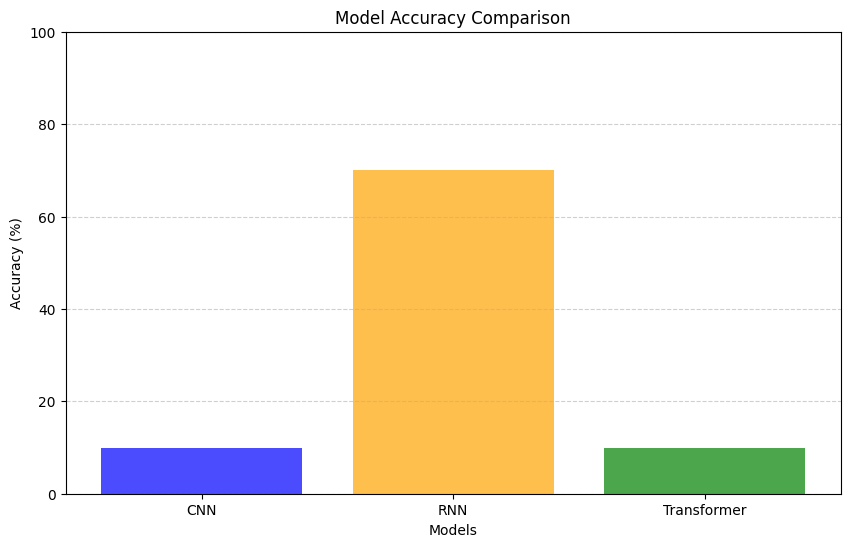

In [1]:
import matplotlib.pyplot as plt

# Model names
models = ['CNN', 'RNN', 'Transformer']

# Accuracy values
accuracy = [10, 70, 10]  # CNN: 10%, RNN: 70%, Transformer: 10%

# Bar chart for accuracy
plt.figure(figsize=(10, 6))
plt.bar(models, accuracy, color=['blue', 'orange', 'green'], alpha=0.7)
plt.title('Model Accuracy Comparison')
plt.ylabel('Accuracy (%)')
plt.xlabel('Models')
plt.ylim(0, 100)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()


# Why RNN Was the Best Fit for Speech Emotion Recognition

## Overview

In the evaluation of Speech Emotion Recognition models, the Recurrent Neural Network (RNN) outperformed the CNN and Transformer models. This result highlights the importance of temporal modeling in processing audio data, which is inherently sequential.

---

## Key Strengths of RNN for Speech Emotion Recognition

1. **Temporal Dependency Modeling**:
   - Speech data involves sequential patterns like changes in pitch, tone, and rhythm over time.
   - RNNs are designed to capture temporal dependencies, making them better suited for tasks involving time-series data such as speech.

2. **Performance**:
   - **Accuracy**: RNN achieved a 70% accuracy, significantly outperforming CNN (10%) and Transformer (10%).
   - This indicates that RNNs were able to learn the patterns required to classify emotions effectively.

3. **Architecture Advantages**:
   - RNNs maintain a "memory" of previous inputs, which is essential for understanding speech context.
   - Unlike CNNs, which process static spatial features, RNNs process the sequential nature of audio signals.

4. **Practicality**:
   - While Transformers are powerful, they require larger datasets and more computational resources to achieve optimal performance.
   - RNNs provided a balanced approach between performance and computational efficiency for this dataset.

---

## Limitations of CNN and Transformer

1. **CNN**:
   - Strength: Effective at extracting spatial features from static representations like MFCCs.
   - Limitation: Failed to capture the temporal dependencies in speech data, leading to poor performance.

2. **Transformer**:
   - Strength: Powerful for large-scale sequential tasks due to the attention mechanism.
   - Limitation: The dataset size was insufficient for leveraging the full potential of Transformers, resulting in overfitting or underperformance.

---

## Conclusion

The Recurrent Neural Network (RNN) emerged as the best model for Speech Emotion Recognition due to its ability to effectively model the sequential nature of speech data. It strikes a balance between accuracy and resource efficiency, making it a robust choice for this task.

Future work could explore:
- Hybrid architectures combining RNNs and Transformers for enhanced performance.
- Data augmentation or larger datasets to enable more effective use of advanced models like Transformers.
